<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and response provenance](README.md)

# 01 · Time in the pit box is only part of time on pit road

A quick stationary service does not imply a short total pit-road visit. We will separate those measurements, keep untimed visits visible, and compare four-wheel changes by the flag state at entry. Then we will change that one contextual choice while holding the race fixed.

**One historical race: 2026 Cup race 5601.** Default replay serves three complete, unmodified first-party NASCAR JSON responses captured on **2026-11-14 UTC**, through the real pinned worker. Live mode re-requests the same race. These are descriptive timing observations, not a crew-performance ranking or an estimate of positions caused by a pit stop.

## Choose the source mode and entry context

`DATA_MODE` is **"replay"** or **"live"**. Replay rejects requests outside the recorded paths; live has no fixture fallback. `ENTRY_FLAG_STATE` is **1 (green)** or **2 (yellow)**. Default **1** selects green-flag entries; the experiment changes it to **2**.

The analytical cohort always requires `stop_type='FOUR_WHEEL_CHANGE'`, four reported tire changes, and all four duration fields available. Flag state describes the instant of entry; it need not remain unchanged throughout the visit. Race ID and season are fixed in visible SQL. Restart Kernel → Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; both request race 5601, season 2026
ENTRY_FLAG_STATE = 1  # 1 = green; experiment: 2 = yellow

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from decimal import Decimal
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import FixedLocator, StrMethodFormatter

from replay_source import ReplaySource, request_key

assert DATA_MODE in {"replay", "live"}
assert (
    isinstance(ENTRY_FLAG_STATE, int)
    and not isinstance(ENTRY_FLAG_STATE, bool)
    and ENTRY_FLAG_STATE in {1, 2}
)
manifest = json.loads(Path("fixtures/manifest.json").read_text())
previous_base = os.environ.pop("NASCAR_BASE_URL", None)
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
os.environ["NASCAR_BASE_URL"] = replay.url if replay else "https://cf.nascar.com"
started = datetime.now(UTC)
flag_names = {1: "Green entry", 2: "Yellow entry"}
colors = {1: "#287d85", 2: "#bd8128"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def duration_axis(ax, which, maximum):
    getattr(ax, "set_" + which + "scale")("symlog", linthresh=1)
    axis = getattr(ax, which + "axis")
    axis.set_major_locator(
        FixedLocator([x for x in [0, 1, 5, 10, 30, 100, 300, 1000, 3000, 10000] if x <= maximum])
    )
    axis.set_major_formatter(StrMethodFormatter("{x:g}"))
    axis.set_minor_locator(FixedLocator([]))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: NASCAR first-party feeds · 2026 Cup race 5601 · {DATA_MODE} · {source_time}",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.93))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nascar/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nascar/notebooks/pyproject.toml.

## Retrieve one race, keeping every visit before filtering

The literal Git revision includes the worker's existing fix that maps negative duration sentinels to NULL; release v0.2.0 predates that fix. uv builds the remote revision in its cache without requiring a local worker checkout.

Passing the season bounds race lookup to one season list. The worker reads that list, this race's weekend feed and its pit feed; it does not retrieve each race in the season. Materialize all results and visits once. SQL filters and charts below query only those local tables. Required empty data fails validation: this worker treats upstream 403/404 as unavailable, so an empty result would not prove a race had no stops.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nascar' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-nascar@11c952ed289db479f5ee81cdd6c5ebc14d0fc3c5 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with httpx2==2.16.0 --with pyarrow==25.0.1 vgi-nascar'
);
CREATE TABLE results AS SELECT * FROM nascar.main.race_results(5601,season:=2026);
CREATE TABLE stops AS SELECT * FROM nascar.main.pit_stops(5601,season:=2026);

,Count


In [4]:
%%sql availability <<
SELECT pit_in_flag_state,stop_type,count(*) AS visits,
 count(stop_seconds) AS timed_box,count(pit_road_seconds) AS timed_road,
 count(*) FILTER(WHERE stop_seconds IS NULL OR pit_road_seconds IS NULL
  OR in_travel_seconds IS NULL OR out_travel_seconds IS NULL) AS incomplete_durations
FROM stops GROUP BY ALL ORDER BY pit_in_flag_state,stop_type;

In [5]:
retrieved = datetime.now(UTC)
source_time = (manifest["capture_finished_utc"] if replay else retrieved.isoformat())[:19] + " UTC"
race_name, track_name = con.execute("SELECT DISTINCT race_name,track_name FROM results").fetchone()
assert con.execute("SELECT count(*) FROM results").fetchone()[0] > 0
assert con.execute("SELECT count(*) FROM stops").fetchone()[0] > 0
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT car_number,stop_number FROM stops GROUP BY ALL HAVING count(*)<>1)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT driver_id FROM results GROUP BY driver_id HAVING count(*)<>1 OR driver_id IS NULL)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM stops s LEFT JOIN results r USING(driver_id) WHERE r.driver_id IS NULL"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM stops WHERE pit_road_seconds<0 OR stop_seconds<0 OR in_travel_seconds<0 OR out_travel_seconds<0"
    ).fetchone()[0]
    == 0
)
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute(
            "SELECT car_number,stop_number,driver_id,pit_in_flag_state,stop_type,pit_road_seconds,stop_seconds,in_travel_seconds,out_travel_seconds FROM stops ORDER BY car_number,stop_number"
        ).fetchall(),
        default=str,
        separators=(",", ":"),
    ).encode()
).hexdigest()
if replay:
    assert sorted(map(request_key, replay.requests)) == sorted(
        request_key(e["request_path"]) for e in manifest["entries"]
    )
    raw = json.loads(Path("fixtures/pit-stops.json").read_text())
    assert len(raw) == int(availability.visits.sum())
    for field, column in [
        ("total_duration", "pit_road_seconds"),
        ("pit_stop_duration", "stop_seconds"),
        ("in_travel_duration", "in_travel_seconds"),
        ("out_travel_duration", "out_travel_seconds"),
    ]:
        expected = sum(row.get(field) is None or Decimal(str(row[field])) < 0 for row in raw)
        assert expected == con.execute(f"SELECT count(*) FROM stops WHERE {column} IS NULL").fetchone()[0]
    request_note = f"Replay served **{len(replay.requests)} exact recorded requests**, and all **{len(raw)} raw visits** survive parsing. Each duration's raw missing/negative count agrees with its SQL NULL count."
else:
    request_note = f"Live retrieval ran from **{started.isoformat()}** to **{retrieved.isoformat()}**. HTTP attempts are not instrumented; retries may occur."
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/request-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requests": replay.requests if replay else None,
            "fingerprint": fingerprint,
            "started_utc": started.isoformat(),
            "finished_utc": retrieved.isoformat(),
        },
        indent=2,
    )
)
display(availability)
prose(
    f"**{race_name}, {track_name}.** {request_note} The table includes pre-race and checkered-flag visits as well as race-time entries. Untimed does not mean instantaneous. Source time: **{source_time}**. Visit fingerprint: `{fingerprint}`."
)

,pit_in_flag_state,stop_type,visits,timed_box,timed_road,incomplete_durations
0,1,FOUR_WHEEL_CHANGE,126,126,125,1
1,1,OTHER,1,0,0,1
2,2,FOUR_WHEEL_CHANGE,87,87,87,0
3,2,ONE_WHEEL_CHANGE,1,1,1,0
4,2,OTHER,12,12,12,0
5,2,TWO_WHEEL_CHANGE_RIGHT,1,1,1,0
6,4,OTHER,16,0,0,16
7,8,OTHER,41,1,39,40


**NASCAR Cup Series Championship Race, Homestead-Miami Speedway.** Replay served **3 exact recorded requests**, and all **285 raw visits** survive parsing. Each duration's raw missing/negative count agrees with its SQL NULL count. The table includes pre-race and checkered-flag visits as well as race-time entries. Untimed does not mean instantaneous. Source time: **2026-11-14T08:26:09 UTC**. Visit fingerprint: `eeeda1ca5d9e248717509c62e07e7587c2e12166be116eeca9d34e2725b80ccc`.

## Define comparable service, then check the components

First restrict to green/yellow entries reported as four-wheel changes with four tires changed. Require all durations for the component comparison, reporting every excluded row. Keep legitimate zero duration values if present; only missing values are excluded.

For a timed visit, `pit_road_seconds ≈ in_travel_seconds + stop_seconds + out_travel_seconds`. The feed rounds these durations to milliseconds, so the check allows **0.003 seconds** of combined rounding difference. Non-box time is calculated per visit as `road − box`; do not subtract separately computed medians and call that the median non-box time.

A service label does not guarantee a routine visit. Inspect the longest reported visits below; retain them in the analysis. The charts use **symmetric logarithmic scales, linear from 0 to 1 second**, to keep long visits and the main timing distribution visible together. Boxes show the middle 50% and median; whiskers extend to observations within 1.5 interquartile ranges, with more distant values shown as dots.

In [6]:
%%sql
CREATE TABLE candidates AS
SELECT * FROM stops WHERE pit_in_flag_state IN (1,2)
 AND stop_type='FOUR_WHEEL_CHANGE' AND tires_changed=4;
CREATE TABLE comparable AS
SELECT *,pit_road_seconds-stop_seconds AS non_box_seconds,
 pit_road_seconds-in_travel_seconds-stop_seconds-out_travel_seconds AS component_residual
FROM candidates WHERE pit_road_seconds IS NOT NULL AND stop_seconds IS NOT NULL
 AND in_travel_seconds IS NOT NULL AND out_travel_seconds IS NOT NULL;
CREATE TABLE selected AS
SELECT * FROM comparable WHERE pit_in_flag_state={{ENTRY_FLAG_STATE}};

,Count


In [7]:
%%sql cohorts <<
SELECT c.pit_in_flag_state,count(*) AS candidate_visits,count(t.stop_number) AS complete_visits,
 count(*)-count(t.stop_number) AS excluded_incomplete,
 median(t.stop_seconds) AS median_box_seconds,
 median(t.pit_road_seconds) AS median_road_seconds,
 median(t.non_box_seconds) AS median_non_box_seconds,
 count(*) FILTER(WHERE t.pit_out_flag_state<>t.pit_in_flag_state) AS changed_flag_during_visit
FROM candidates c LEFT JOIN comparable t USING(car_number,stop_number)
GROUP BY c.pit_in_flag_state ORDER BY c.pit_in_flag_state;

In [8]:
%%sql long_visits <<
SELECT driver_name,car_number,stop_number,lap,pit_in_flag_state,
 stop_seconds,pit_road_seconds,non_box_seconds
FROM comparable ORDER BY pit_road_seconds DESC,car_number,stop_number LIMIT 3;

,pit_in_flag_state,candidate_visits,complete_visits,excluded_incomplete,median_box_seconds,median_road_seconds,median_non_box_seconds,changed_flag_during_visit
0,1,126,125,1,9.976,36.523,26.520,0
1,2,87,87,0,9.976,37.115,27.073,0


,driver_name,car_number,stop_number,lap,pit_in_flag_state,stop_seconds,pit_road_seconds,non_box_seconds
0,Corey Heim,67,3,55,1,397.916,2344.381,1946.465
1,Brad Keselowski,6,5,167,2,78.236,106.292,28.056
2,Austin Dillon,3,5,167,2,64.716,98.021,33.305


**212 of 213 candidate visits** have all four durations; **1** excluded from component comparisons. Largest absolute component residual: **0.001 s**. **0 visits** have different entry and exit flag codes, so entry context should not be read as a claim about the entire visit.

The longest reported visit is **2344.381 s** on pit road, including **397.916 s** stationary, for **Corey Heim**, car **67**, visit **3**. It remains in the cohort. Timing completeness and a four-wheel-change label do not establish a routine service; no cause is inferred from these fields.

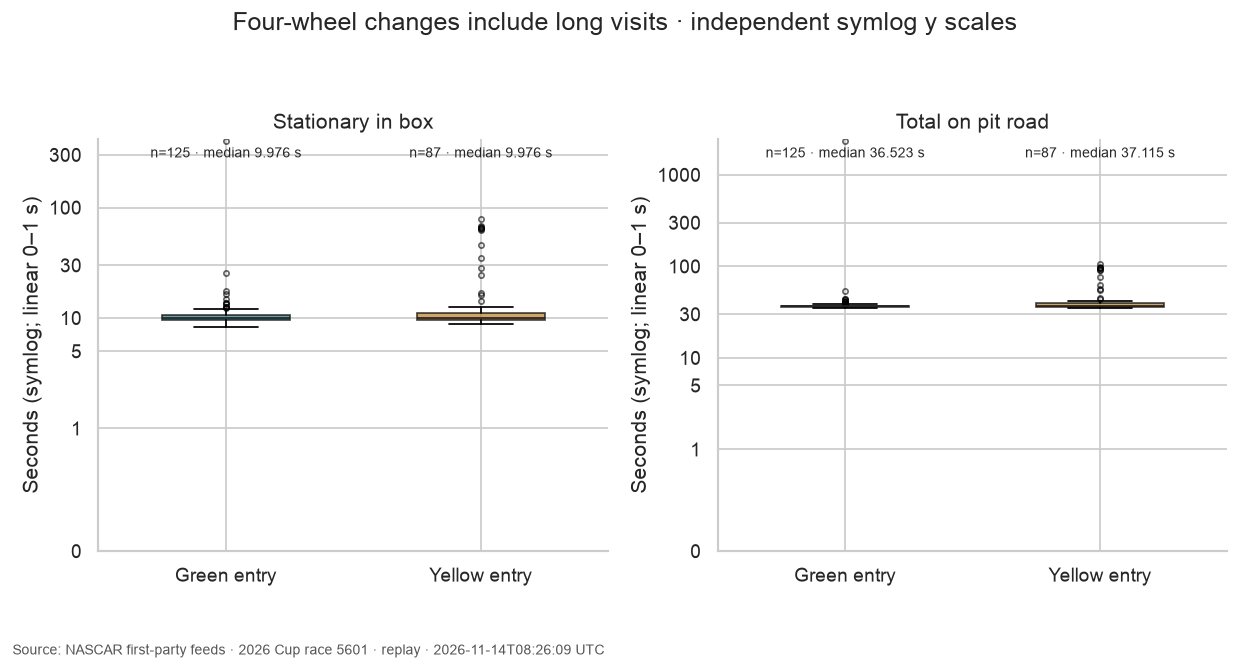

In [9]:
display(cohorts)
display(long_visits)
assert len(cohorts) == 2 and (cohorts.complete_visits > 0).all()
residual = con.execute("SELECT max(abs(component_residual)) FROM comparable").fetchone()[0]
assert residual <= Decimal("0.003")
assert con.execute("SELECT count(*) FROM comparable WHERE non_box_seconds<0").fetchone()[0] == 0
prose(
    f"**{int(cohorts.complete_visits.sum())} of {int(cohorts.candidate_visits.sum())} candidate visits** have all four durations; **{int(cohorts.excluded_incomplete.sum())}** excluded from component comparisons. Largest absolute component residual: **{residual:.3f} s**. **{int(cohorts.changed_flag_during_visit.sum())} visits** have different entry and exit flag codes, so entry context should not be read as a claim about the entire visit."
)
longest = long_visits.iloc[0]
prose(
    f"The longest reported visit is **{longest.pit_road_seconds:.3f} s** on pit road, including **{longest.stop_seconds:.3f} s** stationary, for **{longest.driver_name}**, car **{longest.car_number}**, visit **{longest.stop_number}**. It remains in the cohort. Timing completeness and a four-wheel-change label do not establish a routine service; no cause is inferred from these fields."
)
all_timed = con.execute("SELECT * FROM comparable ORDER BY pit_in_flag_state,car_number,stop_number").df()
fig, axes = plt.subplots(1, 2, figsize=(10, 5.3))
for ax, col, title in zip(
    axes, ["stop_seconds", "pit_road_seconds"], ["Stationary in box", "Total on pit road"], strict=True
):
    groups = [
        all_timed.loc[all_timed.pit_in_flag_state == flag, col].astype(float).to_numpy() for flag in [1, 2]
    ]
    box = ax.boxplot(
        groups,
        tick_labels=["Green entry", "Yellow entry"],
        patch_artist=True,
        widths=0.5,
        medianprops={"color": "#222222"},
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.6},
    )
    for patch, flag in zip(box["boxes"], [1, 2], strict=True):
        patch.set_facecolor(colors[flag])
        patch.set_alpha(0.7)
    for i, (values, flag) in enumerate(zip(groups, [1, 2], strict=True), start=1):
        median = float(
            cohorts.loc[
                cohorts.pit_in_flag_state == flag,
                "median_box_seconds" if col == "stop_seconds" else "median_road_seconds",
            ].iloc[0]
        )
        ax.text(
            i,
            0.98,
            f"n={len(values)} · median {median:.3f} s",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=8,
        )
    ax.set(title=title, ylabel="Seconds (symlog; linear 0–1 s)")
    ax.set_ylim(bottom=0)
    ax.margins(y=0.25)
    duration_axis(ax, "y", max(max(v) for v in groups) * 1.25)
fig.suptitle("Four-wheel changes include long visits · independent symlog y scales")
finish(fig)

## Examine the selected context without turning association into causation

Plot stationary time against total time for the selected entry state. Each dot is a visit, not a driver; a driver can appear several times. The diagonal marks equal box and road time. In the original seconds, road minus box is non-box time; visual distances on the nonlinear axes are not differences in seconds. Neither is a measured loss relative to staying on track.

Both axes use the complete green/yellow comparison cohort, so the default and experiment share scales. Flag state, traffic, pit-box location, strategy and visit selection can differ; this comparison does not isolate a crew effect or translate seconds into finishing positions.

In [10]:
%%sql selection <<
SELECT count(*) AS visits,count(DISTINCT driver_id) AS drivers,
 median(stop_seconds) AS median_box_seconds,
 median(pit_road_seconds) AS median_road_seconds,
 median(non_box_seconds) AS median_non_box_seconds,
 min(stop_seconds) AS minimum_box_seconds,max(stop_seconds) AS maximum_box_seconds
FROM selected;

,visits,drivers,median_box_seconds,median_road_seconds,median_non_box_seconds,minimum_box_seconds,maximum_box_seconds
0,125,40,9.976,36.523,26.52,8.276,397.916


**Green entry:** **125 visits by 40 drivers**, with median box time **9.976 s**, median total road time **36.523 s**, and median per-visit non-box time **26.520 s**. These are three separately calculated medians; they need not add exactly. A shorter box time alone cannot account for the full road-time distribution.

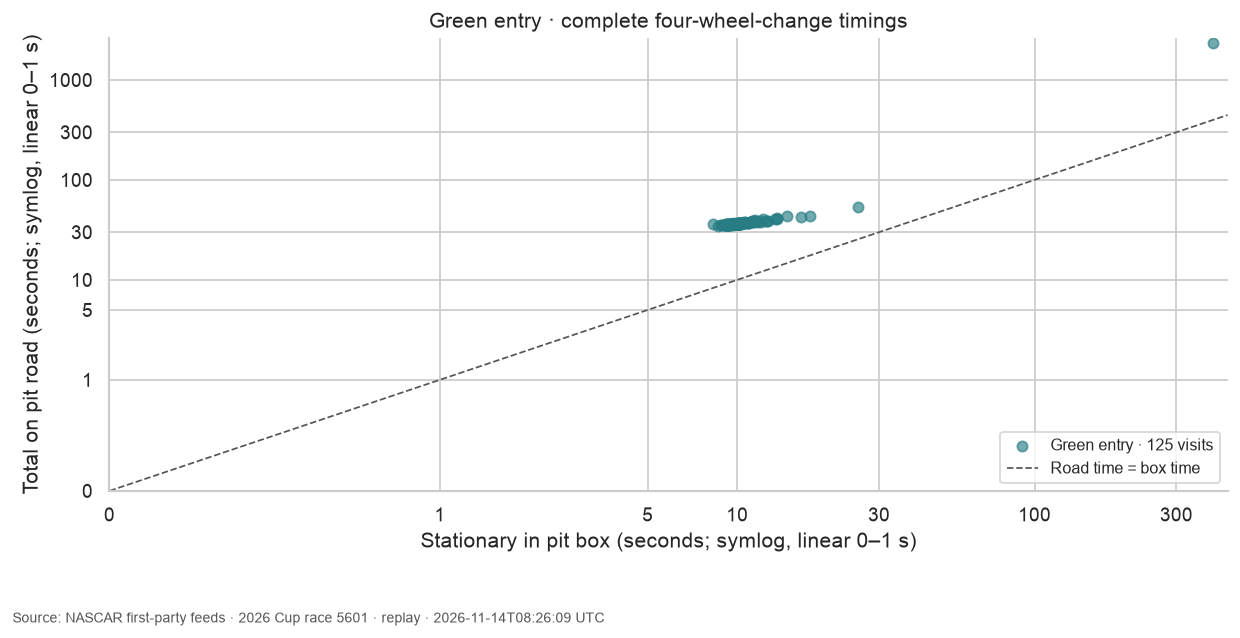

In [11]:
display(selection)
s = selection.iloc[0]
assert s.visits > 0
assert (
    con.execute("SELECT count(*) FROM selected WHERE pit_in_flag_state<>?", [ENTRY_FLAG_STATE]).fetchone()[0]
    == 0
)
prose(
    f"**{flag_names[ENTRY_FLAG_STATE]}:** **{int(s.visits)} visits by {int(s.drivers)} drivers**, with median box time **{s.median_box_seconds:.3f} s**, median total road time **{s.median_road_seconds:.3f} s**, and median per-visit non-box time **{s.median_non_box_seconds:.3f} s**. These are three separately calculated medians; they need not add exactly. A shorter box time alone cannot account for the full road-time distribution."
)
selected = all_timed[all_timed.pit_in_flag_state == ENTRY_FLAG_STATE]
xmax = max(float(all_timed.stop_seconds.max()) * 1.12, 1)
ymax = max(float(all_timed.pit_road_seconds.max()) * 1.12, xmax)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(
    selected.stop_seconds,
    selected.pit_road_seconds,
    color=colors[ENTRY_FLAG_STATE],
    alpha=0.65,
    s=35,
    label=f"{flag_names[ENTRY_FLAG_STATE]} · {len(selected)} visits",
)
ax.plot([0, xmax], [0, xmax], color="#555555", linestyle="--", linewidth=1, label="Road time = box time")
ax.set(
    xlim=(0, xmax),
    ylim=(0, ymax),
    xlabel="Stationary in pit box (seconds; symlog, linear 0–1 s)",
    ylabel="Total on pit road (seconds; symlog, linear 0–1 s)",
    title=f"{flag_names[ENTRY_FLAG_STATE]} · complete four-wheel-change timings",
)
duration_axis(ax, "x", xmax)
duration_axis(ax, "y", ymax)
ax.legend(loc="lower right", fontsize=9)
finish(fig)

## Experiment: change only green entry to yellow entry

Keep `DATA_MODE="replay"` and change `ENTRY_FLAG_STATE` from **1 to 2**. Predict that the selected visit count and distribution will change, but leave the direction of the median differences open. Compare box, road and per-visit non-box medians, and the scatterplot on its unchanged axes.

The full-corpus availability table, two-context boxplots, component identity and visit fingerprint must remain unchanged. Restore **1** afterwards. This is a change of observed cohort; it is not a randomized comparison of flag states or a causal estimate of time saved.

In [12]:
con.close()
if replay:
    replay.close()
if previous_base is None:
    os.environ.pop("NASCAR_BASE_URL", None)
else:
    os.environ["NASCAR_BASE_URL"] = previous_base

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)